# Clasificación supervisada de la popularidad musical mediante LightGBM

## Objetivo

El objetivo de este notebook es desarrollar y evaluar un modelo de clasificación supervisada capaz de predecir la categoría de popularidad de una canción a partir de sus características musicales.

Para ello, se utilizará **LightGBM (Light Gradient Boosting Machine)**, un algoritmo de ensamblaje basado en gradient boosting que construye árboles de decisión de manera secuencial. El algoritmo utiliza una estrategia de crecimiento de árboles orientada a hojas (*leaf-wise*), buscando reducir la función de pérdida en cada iteración.

El análisis contempla las siguientes etapas:

- Carga de los datasets de entrenamiento y prueba.
- Separación de las variables predictoras y la variable objetivo.
- Búsqueda de hiperparámetros mediante RandomizedSearchCV.
- Entrenamiento del modelo LightGBM con los hiperparámetros seleccionados.
- Evaluación del rendimiento durante la búsqueda de hiperparámetros.
- Evaluación final sobre el conjunto de prueba.
- Análisis de las matrices de confusión.
- Identificación de las características con mayor importancia para el modelo.
- Comparación de los modelos mediante KFold, StratifiedKFold y LeavePOut.

La variable objetivo será `popularity_category`, que representa la categoría de popularidad asignada a cada canción.

**Alcance de esta adaptación:** el notebook de comparación proporcionado contiene LightGBM Base y LightGBM + RandomizedSearchCV. No contiene una búsqueda GridSearchCV de LightGBM; por ello, se conservan esos dos modelos y no se atribuyen resultados a una búsqueda que no aparece en los datos de origen.

In [2]:
import pandas as pd
from math import comb
import os
import sys

import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import randint, uniform, loguniform
from lightgbm import LGBMClassifier

from sklearn.model_selection import (
    KFold,
    StratifiedKFold,
    LeavePOut,
    RandomizedSearchCV,
    cross_validate,
    train_test_split
)

from sklearn.metrics import (
    confusion_matrix,
    accuracy_score,
    balanced_accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report
)

# En caso de que Python no encuentre en la ruta los otros directorios,
# ejecutar esta configuración
sys.path.append(os.path.abspath(".."))


# CONSIDERACIÓN: Si los hiperparámetros ya están encontrados,
# la variable ENCONTRADO debe mantener el valor True o en False
# en caso de que se deban encontrar nuevamente.

ENCONTRADO = True

---

## Carga de los datasets de entrenamiento y prueba

Se cargan dos datasets previamente preprocesados:

- **Conjunto de entrenamiento:** se utiliza para buscar los mejores hiperparámetros y ajustar el modelo.
- **Conjunto de prueba:** se reserva para evaluar el rendimiento final del modelo sobre observaciones que no participan en la búsqueda ni en el entrenamiento.

Ambos conjuntos deben mantener la misma estructura de variables predictoras, incluyendo el mismo orden y las mismas transformaciones aplicadas previamente.

Finalmente, se muestran las primeras filas de cada dataset para verificar su carga y observar la estructura de los datos.

In [3]:
data_train = pd.read_csv(
    "../../../dataset/Spotify_train_preprocesado_clasificacion.csv"
)

data_test = pd.read_csv(
    "../../../dataset/Spotify_test_preprocesado_clasificacion.csv"
)

df_train = data_train.copy()
df_test = data_test.copy()

print("Dataset de entrenamiento:")
display(df_train.head())

print("\nDataset de prueba:")
display(df_test.head())

Dataset de entrenamiento:


,bin__track_genre_0,bin__track_genre_1,bin__track_genre_2,bin__track_genre_3,bin__track_genre_4,bin__track_genre_5,bin__track_genre_6,ord__duration_category,num__danceability,num__energy,...,num__loudness,num__mode,num__speechiness,num__acousticness,num__instrumentalness,num__liveness,num__valence,num__tempo,num__duration_min,popularity_category
0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,-0.360656,0.407609,0.005418,...,-0.557598,0.751125,-0.804229,0.532848,-0.562123,-0.436477,1.542740,-0.147610,-0.695300,1
1,0.0,0.0,0.0,0.0,0.0,1.0,0.0,-0.360656,0.100464,-0.034422,...,-0.017461,0.751125,-0.785413,0.623235,-0.606882,-0.678120,1.183864,0.437714,-0.191994,0
2,0.0,0.0,0.0,0.0,0.0,1.0,1.0,0.927115,-1.881489,0.216573,...,0.430609,0.751125,-0.519639,-0.618079,-0.580263,-0.985860,-1.305115,0.437984,0.625209,2
3,0.0,0.0,0.0,0.0,1.0,0.0,0.0,-0.360656,1.746296,0.336094,...,0.571210,-1.331337,-0.500823,-0.710274,-0.606882,-0.635477,-0.506326,0.064335,-0.879964,0
4,0.0,0.0,0.0,0.0,1.0,0.0,1.0,-0.360656,0.726344,-1.795371,...,-2.390784,-1.331337,1.124396,1.430692,1.793755,-0.671013,1.195440,2.664353,-0.772929,2



Dataset de prueba:


,bin__track_genre_0,bin__track_genre_1,bin__track_genre_2,bin__track_genre_3,bin__track_genre_4,bin__track_genre_5,bin__track_genre_6,ord__duration_category,num__danceability,num__energy,...,num__loudness,num__mode,num__speechiness,num__acousticness,num__instrumentalness,num__liveness,num__valence,num__tempo,num__duration_min,popularity_category
0,0.0,0.0,1.0,0.0,0.0,1.0,0.0,0.927115,-1.452645,-1.914892,...,-2.318107,0.751125,-0.700742,1.813330,1.793755,-0.700153,-1.619613,-0.133029,1.330330,0
1,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.360656,1.798453,0.626930,...,1.478109,0.751125,0.865678,-0.675324,-0.606764,1.390062,1.450127,-0.406397,-0.528812,0
2,1.0,0.0,0.0,0.0,0.0,0.0,0.0,-0.360656,0.639416,0.224541,...,0.842404,0.751125,-0.199770,-0.940037,-0.606785,-0.724317,1.303489,2.353574,-0.550148,0
3,1.0,0.0,0.0,0.0,1.0,1.0,0.0,-1.648427,-0.067596,0.754419,...,0.438615,0.751125,2.126046,1.707878,-0.606882,2.409939,0.292462,-1.350621,-1.566635,1
4,1.0,0.0,1.0,0.0,1.0,1.0,1.0,0.927115,0.830657,1.093063,...,1.257701,0.751125,-0.380872,-0.942719,1.793755,-1.048403,1.006355,0.096426,1.158399,0


---

## Separación de variables predictoras y variable objetivo

Se separan las variables utilizadas para realizar las predicciones de la variable que se desea estimar.

- **X_train:** características musicales del conjunto de entrenamiento.
- **y_train:** categorías de popularidad correspondientes al conjunto de entrenamiento.
- **X_test:** características musicales del conjunto de prueba.
- **y_test:** categorías reales de popularidad del conjunto de prueba.

La variable `popularity_category` se excluye de las variables predictoras para evitar que el modelo utilice directamente la respuesta que debe aprender a predecir.

Se utilizan directamente las categorías codificadas presentes en los datasets, sin aplicar transformaciones adicionales.

In [4]:
# Separación de variables predictoras y objetivo
X_train = df_train.drop(
    columns=["popularity_category"]
)

y_train = df_train["popularity_category"]

X_test = df_test.drop(
    columns=["popularity_category"]
)

y_test = df_test["popularity_category"]

---

## Búsqueda de hiperparámetros mediante RandomizedSearchCV

Antes de entrenar el modelo definitivo, se realiza una búsqueda de hiperparámetros para identificar una configuración que permita mejorar el rendimiento de LightGBM.

Se utiliza `RandomizedSearchCV`, que selecciona aleatoriamente combinaciones de valores dentro de un espacio de búsqueda definido. Este procedimiento permite explorar configuraciones sin evaluar todas las combinaciones posibles.

Se consideran los siguientes hiperparámetros:

- `n_estimators`: cantidad de árboles que se construyen secuencialmente.
- `learning_rate`: controla la contribución de cada árbol nuevo al modelo.
- `num_leaves`: cantidad máxima de hojas por árbol; controla su complejidad.
- `max_depth`: profundidad máxima del árbol. El valor `-1` permite que no exista un límite explícito.
- `min_child_samples`: cantidad mínima de observaciones que debe contener una hoja.
- `subsample`: proporción de observaciones utilizadas para entrenar cada iteración.
- `colsample_bytree`: proporción de variables predictoras utilizadas para construir cada árbol.
- `reg_alpha`: regularización L1.
- `reg_lambda`: regularización L2.

Se utiliza **F1-Macro** como única métrica de selección y comparación, ya que asigna la misma importancia a todas las categorías de popularidad, independientemente de su frecuencia.

**Configuración reproducida:** la búsqueda original de LightGBM utilizó `StratifiedKFold` con tres particiones y 40 combinaciones. Esta configuración se conserva para que los hiperparámetros encontrados sean consistentes con los resultados registrados en el notebook de comparación. La evaluación posterior incluirá además los métodos de validación utilizados en el notebook de XGBoost.

**Consideración metodológica:** el conjunto de prueba no participa en la búsqueda de hiperparámetros. De esta manera, se reserva para la evaluación final de la capacidad de generalización del modelo.

---

## Configuración de la búsqueda de hiperparámetros

In [5]:
# Configuración de la validación cruzada utilizada en la búsqueda
cv = StratifiedKFold(
    n_splits=3,
    shuffle=True,
    random_state=42
)

# Modelo base de LightGBM
lgbm_base = LGBMClassifier(
    random_state=42,
    n_jobs=1,
    verbose=-1,
    subsample_freq=1
)

# Espacio de búsqueda de hiperparámetros
param_distributions = {
    "n_estimators": randint(200, 1201),
    "learning_rate": loguniform(0.01, 0.3),
    "num_leaves": randint(15, 256),
    "max_depth": [-1, 6, 8, 10, 12, 16],
    "min_child_samples": randint(5, 101),
    "subsample": uniform(0.5, 0.5),
    "colsample_bytree": uniform(0.4, 0.6),
    "reg_alpha": loguniform(1e-3, 10),
    "reg_lambda": loguniform(1e-3, 10)
}

# Única métrica utilizada para seleccionar los hiperparámetros
scoring = "f1_macro"

---

## Búsqueda de hiperparámetros con RandomizedSearchCV

In [6]:
if ENCONTRADO == False:

    random_search = RandomizedSearchCV(
        estimator=lgbm_base,
        param_distributions=param_distributions,
        n_iter=40,
        scoring=scoring,
        refit=True,
        cv=cv,
        verbose=1,
        random_state=42,
        n_jobs=-1,
        return_train_score=True
    )

    random_search.fit(X_train, y_train)

---

## Resultados de la búsqueda de hiperparámetros con RandomizedSearchCV

Una vez finalizada la búsqueda, se identifica la combinación de hiperparámetros que obtuvo el mejor resultado promedio de F1-Macro durante la validación cruzada.

Se presentan los mejores parámetros encontrados y el F1-Macro promedio de la mejor configuración.

Además, se muestra una tabla con las diez mejores combinaciones evaluadas, ordenadas según su F1-Macro promedio. La desviación estándar permite observar la variabilidad del resultado entre las particiones.

In [7]:
if ENCONTRADO == False:

    print("Mejores hiperparámetros encontrados con RandomizedSearchCV:")

    for parametro, valor in random_search.best_params_.items():
        print(f"{parametro}: {valor}")

    print(
        f"\nMejor F1-Macro promedio: "
        f"{random_search.best_score_:.4f}"
    )

    # Obtener resultados de las configuraciones evaluadas
    resultados_busqueda = pd.DataFrame(random_search.cv_results_)

    columnas_resultados = [
        "rank_test_score",
        "mean_test_score",
        "std_test_score",
        "mean_fit_time",
        "params"
    ]

    resultados_ordenados = resultados_busqueda[
        columnas_resultados
    ].sort_values(
        by="rank_test_score"
    )

    print("\nTop 10 configuraciones evaluadas:")

    display(resultados_ordenados.head(10))

## Resultados previamente obtenidos con LightGBM

El notebook `Comparacion_RF_GridSearch_Random_LightGBM.ipynb` contiene una ejecución de LightGBM sobre los mismos datasets.

Los resultados registrados fueron:

| Modelo | F1-Macro CV | Desviación CV | F1-Macro Test |
|---|---:|---:|---:|
| LightGBM Base | 0.4972 | 0.0041 | 0.5044 |
| LightGBM + RandomizedSearchCV | 0.6159 | 0.0039 | 0.6689 |

La búsqueda aleatoria evaluó 40 combinaciones mediante tres particiones estratificadas. El mejor F1-Macro promedio de validación fue **0.6159**, mientras que el F1-Macro obtenido sobre el conjunto de prueba fue **0.6689**.

La siguiente configuración corresponde a los mejores hiperparámetros que quedaron registrados en esa ejecución. Se utilizan para reproducir el modelo optimizado sin volver a ejecutar una búsqueda que anteriormente tomó aproximadamente 156 minutos.

### Hiperparámetros seleccionados mediante RandomizedSearchCV

| Hiperparámetro | Valor |
|---|---:|
| `n_estimators` | 1187 |
| `learning_rate` | 0.058181 |
| `num_leaves` | 199 |
| `max_depth` | -1 |
| `min_child_samples` | 15 |
| `subsample` | 0.938670 |
| `colsample_bytree` | 0.638543 |
| `reg_alpha` | 0.002844 |
| `reg_lambda` | 4.997749 |

**Importante:** `subsample_freq=1` se mantiene en el clasificador optimizado para activar el uso del parámetro `subsample`, tal como se configuró durante la búsqueda original.

### Diez mejores configuraciones registradas

La siguiente tabla resume las diez mejores configuraciones de la búsqueda aleatoria original. Se muestran únicamente los resultados asociados a F1-Macro, de acuerdo con la métrica seleccionada para el análisis.

| Posición | F1-Macro promedio | Desviación estándar |
|---:|---:|---:|
| 1 | 0.6159 | 0.0039 |
| 2 | 0.6078 | 0.0044 |
| 3 | 0.6073 | 0.0049 |
| 4 | 0.6022 | 0.0028 |
| 5 | 0.6015 | 0.0059 |
| 6 | 0.5982 | 0.0044 |
| 7 | 0.5914 | 0.0021 |
| 8 | 0.5886 | 0.0016 |
| 9 | 0.5879 | 0.0012 |
| 10 | 0.5853 | 0.0042 |

En la mejor configuración, el F1-Macro promedio de entrenamiento fue **0.9819**, mientras que el F1-Macro promedio de validación fue **0.6159**. Esta diferencia amplia sugiere que el modelo puede estar sobreajustándose a los datos de entrenamiento, por lo que es importante considerar el resultado independiente obtenido en test.

---

## Entrenamiento del modelo LightGBM definitivo

Se construye el modelo LightGBM optimizado utilizando los hiperparámetros seleccionados mediante RandomizedSearchCV.

Como la búsqueda ya fue realizada en el notebook de comparación, los valores se recuperan desde la configuración registrada. Si se desea repetir la búsqueda, se debe establecer `ENCONTRADO = False`; en ese caso, el diccionario se actualizará utilizando `random_search.best_params_`.

El modelo definitivo se ajusta con la totalidad del conjunto de entrenamiento y se utilizará para generar predicciones sobre el conjunto de prueba.

In [8]:
# Hiperparámetros encontrados previamente con RandomizedSearchCV
if ENCONTRADO == False:
    hyperparams_random = random_search.best_params_

else:
    hyperparams_random = {
        "colsample_bytree": 0.6385432126525135,
        "learning_rate": 0.058181045951586456,
        "max_depth": -1,
        "min_child_samples": 15,
        "n_estimators": 1187,
        "num_leaves": 199,
        "reg_alpha": 0.0028437674894443675,
        "reg_lambda": 4.997749370303173,
        "subsample": 0.9386696766904905
    }

# Modelo LightGBM optimizado
lgbm_model = LGBMClassifier(
    random_state=42,
    n_jobs=-1,
    verbose=-1,
    subsample_freq=1,
    **hyperparams_random
)

# Entrenamiento definitivo
lgbm_model.fit(X_train, y_train)

print("Modelo LightGBM optimizado:")
print(lgbm_model)

Modelo LightGBM optimizado:
LGBMClassifier(colsample_bytree=0.6385432126525135,
               learning_rate=0.058181045951586456, min_child_samples=15,
               n_estimators=1187, n_jobs=-1, num_leaves=199, random_state=42,
               reg_alpha=0.0028437674894443675, reg_lambda=4.997749370303173,
               subsample=0.9386696766904905, subsample_freq=1, verbose=-1)


---

## Evaluación final del modelo sobre el conjunto de prueba

Se generan predicciones para las observaciones de `X_test`.

Las categorías predichas se comparan con los valores reales de `y_test` mediante F1-Macro, la métrica seleccionada para este análisis.

También se genera un reporte de clasificación que presenta, para cada categoría de popularidad, la precisión, recall, F1-score y cantidad de observaciones. Este reporte permite complementar el valor global de F1-Macro con el comportamiento observado en cada categoría.

In [9]:
# Generar predicciones sobre el conjunto de prueba
y_pred_lgbm = lgbm_model.predict(X_test)

print("Resultados de LightGBM en el conjunto de prueba:")

print(
    f"F1-Macro: "
    f"{f1_score(y_test, y_pred_lgbm, average='macro', zero_division=0):.4f}"
)

print("\nReporte de clasificación:")

print(
    classification_report(
        y_test,
        y_pred_lgbm,
        zero_division=0
    )
)

Resultados de LightGBM en el conjunto de prueba:
F1-Macro: 0.6747

Reporte de clasificación:
              precision    recall  f1-score   support

           0       0.81      0.80      0.80      6742
           1       0.69      0.72      0.70      6615
           2       0.70      0.73      0.71      6615
           3       0.71      0.59      0.65      2522
           4       0.67      0.41      0.51       191

    accuracy                           0.73     22685
   macro avg       0.72      0.65      0.67     22685
weighted avg       0.73      0.73      0.73     22685



---

## Análisis de las matrices de confusión

Se construyen dos matrices de confusión para examinar con mayor detalle los aciertos y errores del modelo.

**Matriz de confusión en cantidades**

Muestra el número de observaciones correspondientes a cada combinación de categoría real y categoría predicha. La diagonal principal representa las predicciones correctas, mientras que los valores fuera de ella representan errores de clasificación.

**Matriz de confusión normalizada**

Presenta los resultados como proporciones respecto del total de observaciones de cada categoría real. Esta normalización permite comparar el comportamiento del modelo entre clases de diferentes tamaños.

En ambas matrices:

- Las filas representan las categorías reales.
- Las columnas representan las categorías predichas.
- La diagonal principal permite identificar la cantidad o proporción de aciertos por categoría.
- Los valores fuera de la diagonal muestran qué categorías tiende a confundir el modelo.

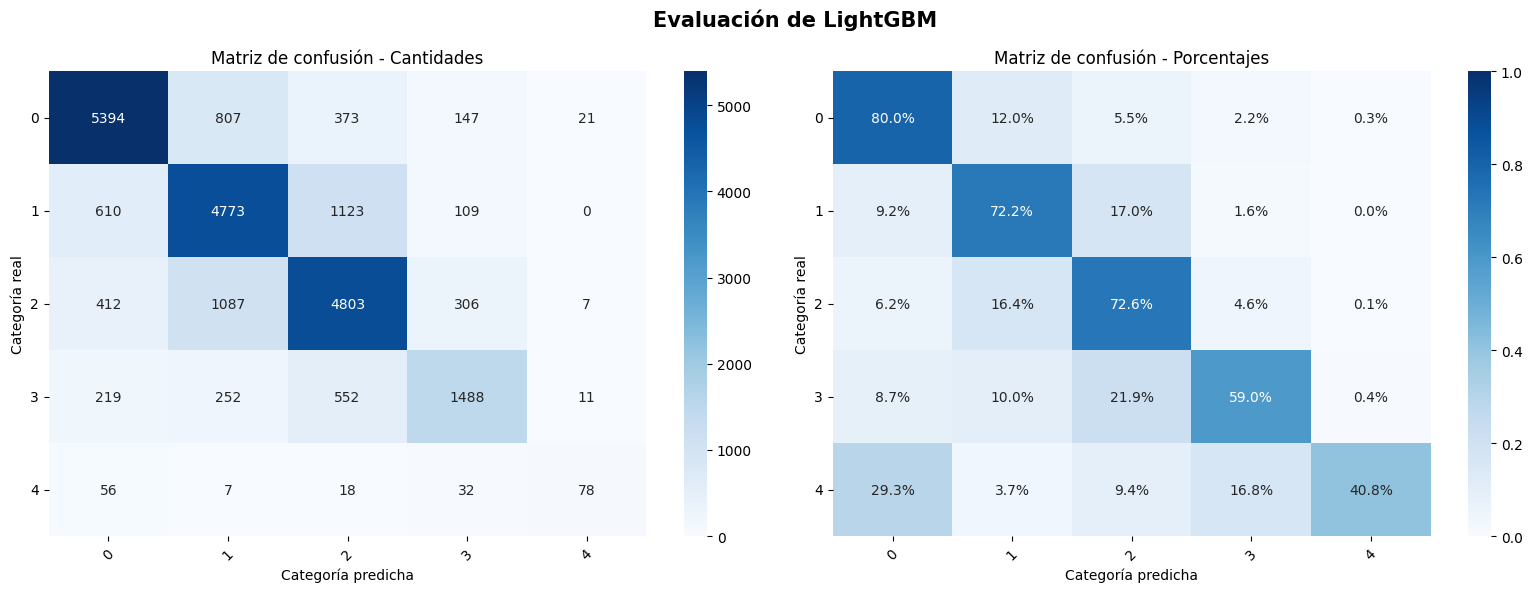

In [10]:
# Obtener las categorías reconocidas por el modelo
etiquetas = lgbm_model.classes_

# Matriz de confusión con valores absolutos
matriz = confusion_matrix(
    y_test,
    y_pred_lgbm,
    labels=etiquetas
)

# Matriz de confusión normalizada por categoría real
matriz_normalizada = confusion_matrix(
    y_test,
    y_pred_lgbm,
    labels=etiquetas,
    normalize="true"
)

# Crear visualizaciones
fig, axes = plt.subplots(1, 2, figsize=(16, 6))

sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=etiquetas,
    yticklabels=etiquetas,
    ax=axes[0]
)

axes[0].set_title("Matriz de confusión - Cantidades")
axes[0].set_xlabel("Categoría predicha")
axes[0].set_ylabel("Categoría real")

sns.heatmap(
    matriz_normalizada,
    annot=True,
    fmt=".1%",
    cmap="Blues",
    vmin=0,
    vmax=1,
    xticklabels=etiquetas,
    yticklabels=etiquetas,
    ax=axes[1]
)

axes[1].set_title("Matriz de confusión - Porcentajes")
axes[1].set_xlabel("Categoría predicha")
axes[1].set_ylabel("Categoría real")

for ax in axes:
    ax.tick_params(axis="x", rotation=45)
    ax.tick_params(axis="y", rotation=0)

plt.suptitle(
    "Evaluación de LightGBM",
    fontsize=15,
    fontweight="bold"
)

plt.tight_layout()
plt.show()

---

## Importancia de las variables

Se examina la importancia de las características utilizadas por LightGBM para construir sus árboles de decisión.

La importancia permite identificar qué variables contribuyen en mayor medida a las decisiones del modelo, de acuerdo con el criterio de importancia proporcionado por LightGBM.

Se ordenan las características de mayor a menor importancia y se presentan las cinco primeras, junto con una visualización de las quince variables más relevantes.

**Consideración:** la importancia de variables describe la contribución dentro del modelo entrenado, pero no implica una relación causal entre una característica musical y la popularidad de una canción.

In [11]:
# Construcción del DataFrame de importancias
importancias = pd.DataFrame({
    "feature": X_train.columns,
    "importance": lgbm_model.feature_importances_
})

importancias = importancias.sort_values(
    by="importance",
    ascending=False
)

print("Top 5 características más importantes:")

display(importancias.head(5))

Top 5 características más importantes:


,feature,importance
17,num__valence,110936
8,num__danceability,109767
18,num__tempo,109568
19,num__duration_min,106885
14,num__acousticness,106665


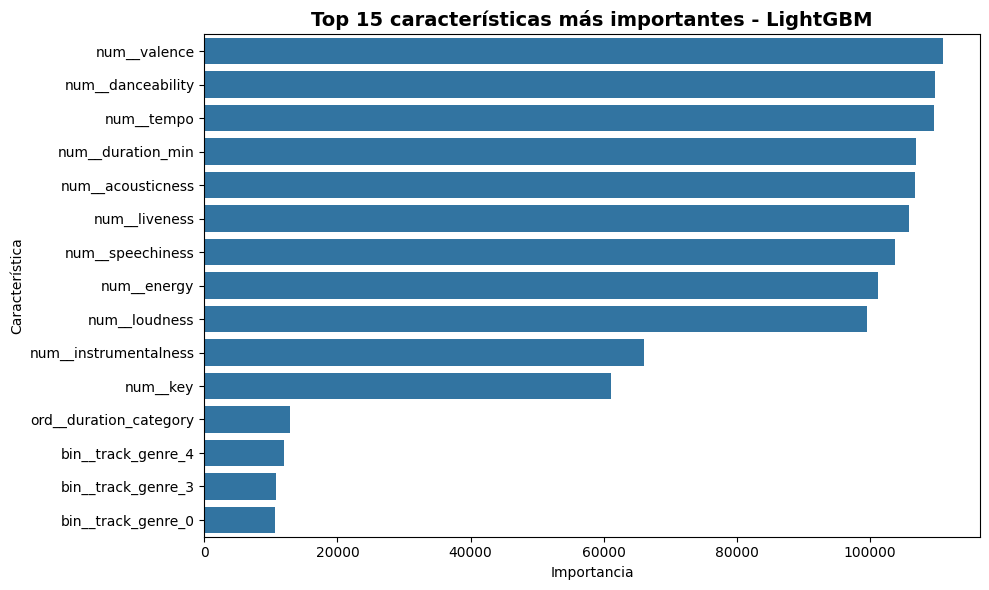

In [12]:
# Visualización de las 15 características más importantes
plt.figure(figsize=(10, 6))

sns.barplot(
    data=importancias.head(15),
    x="importance",
    y="feature"
)

plt.title(
    "Top 15 características más importantes - LightGBM",
    fontsize=14,
    fontweight="bold"
)
plt.xlabel("Importancia")
plt.ylabel("Característica")
plt.tight_layout()
plt.show()

---

# Validación cruzada de los 2 modelos LightGBM desarrollados

En esta sección se comparan dos configuraciones del algoritmo:

- **LightGBM Base:** utiliza la configuración general del clasificador, sin aplicar la búsqueda de hiperparámetros.
- **LightGBM RandomizedSearchCV:** utiliza los hiperparámetros seleccionados mediante la búsqueda aleatoria registrada previamente.

Ambos modelos se evaluarán utilizando KFold, StratifiedKFold y LeavePOut. La métrica utilizada en todas las evaluaciones será F1-Macro.

---

## Configuración de hiperparámetros y muestra para LeavePOut

Se recuperan los hiperparámetros seleccionados mediante RandomizedSearchCV desde `hyperparams_random`. Esta configuración se utilizará para construir el modelo LightGBM optimizado y compararlo con el modelo base.

Además, se prepara una muestra estratificada de 100 observaciones a partir del conjunto de entrenamiento. La estratificación utiliza `y_train` para conservar aproximadamente la distribución original de las categorías en la muestra.

Esta reducción se aplica exclusivamente a LeavePOut, debido al elevado número de combinaciones que genera este método cuando se utiliza sobre conjuntos de datos grandes. Se fija `random_state=42` para que la selección de observaciones sea reproducible.

Finalmente, se configura `LeavePOut(p=2)`. En cada iteración, dos observaciones se reservan para prueba y las restantes se utilizan para entrenar el modelo.

In [13]:
# Selección de una muestra estratificada
X_lpo, _, y_lpo, _ = train_test_split(
    X_train,
    y_train,
    train_size=100,
    stratify=y_train,
    random_state=42
)

# Configuración de LeavePOut
cv_leave_p_out = LeavePOut(p=2)

---

## Construcción de los dos modelos LightGBM

Se instancian dos clasificadores LightGBM para comparar distintas configuraciones:

- **LightGBM base:** utiliza la configuración general del algoritmo, sin incorporar la configuración optimizada.
- **LightGBM con RandomizedSearchCV:** utiliza los valores almacenados en `hyperparams_random`.

Se establece `random_state=42` para favorecer la reproducibilidad y `n_jobs=1` para limitar el paralelismo interno de cada clasificador. Esto resulta útil al ejecutar las validaciones en paralelo mediante `cross_validate`.

Se mantiene `subsample_freq=1` en el modelo optimizado para que el parámetro `subsample` tenga efecto.

En esta sección se construyen clasificadores con las configuraciones seleccionadas previamente; la búsqueda de hiperparámetros no se ejecuta nuevamente.

In [14]:
# Modelo LightGBM base, sin hiperparámetros optimizados
lgbm_base_model = LGBMClassifier(
    random_state=42,
    n_jobs=1,
    verbose=-1
)

# Modelo LightGBM optimizado con RandomizedSearchCV
lgbm_random_model = LGBMClassifier(
    random_state=42,
    n_jobs=1,
    verbose=-1,
    subsample_freq=1,
    **hyperparams_random
)

---

## Configuración de los métodos de validación cruzada

Se definen dos estrategias de validación cruzada, ambas con cinco particiones y mezcla aleatoria de las observaciones:

- **KFold:** divide el conjunto de datos en cinco particiones. En cada iteración, cuatro se utilizan para entrenar y una para evaluar. No considera la distribución de las clases al construir las particiones.
- **StratifiedKFold:** también utiliza cinco particiones, pero procura conservar en cada una la proporción de categorías presente en el conjunto completo.

En ambos casos, `shuffle=True` permite mezclar las observaciones antes de generar las particiones y `random_state=42` permite reproducir la división.

In [15]:
# KFold
cv_kfold = KFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# StratifiedKFold
cv_stratified = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

## Validación cruzada KFold

Se evalúan los dos clasificadores mediante la estrategia KFold, utilizando el conjunto completo de entrenamiento (`X_train` y `y_train`).

La función `cross_validate` realiza el ciclo de entrenamiento y evaluación para cada partición. El procedimiento se aplica por separado al modelo base y al modelo con hiperparámetros seleccionados mediante RandomizedSearchCV.

Se utiliza exclusivamente `F1-Macro` como métrica de evaluación. El argumento `n_jobs=-1` permite distribuir las tareas entre los procesadores disponibles, mientras que cada clasificador utiliza `n_jobs=1` para evitar paralelismo anidado.

In [ ]:
# Validación KFold - LightGBM base
resultados_base_kfold = cross_validate(
    lgbm_base_model,
    X_train,
    y_train,
    cv=cv_kfold,
    scoring="f1_macro",
    n_jobs=-1
)

# Validación KFold - LightGBM RandomizedSearchCV
resultados_random_kfold = cross_validate(
    lgbm_random_model,
    X_train,
    y_train,
    cv=cv_kfold,
    scoring="f1_macro",
    n_jobs=-1
)

## Validación cruzada StratifiedKFold

Se repite la evaluación de los dos clasificadores utilizando StratifiedKFold y el conjunto completo de entrenamiento.

A diferencia de KFold, esta estrategia procura mantener la proporción de las categorías en cada partición. Esta característica es relevante en problemas de clasificación multiclase, especialmente cuando las categorías no tienen la misma frecuencia.

Se mantiene F1-Macro como única métrica, permitiendo comparar los dos modelos bajo la misma medida de rendimiento.

In [ ]:
# Validación StratifiedKFold - LightGBM base
resultados_base_stratified = cross_validate(
    lgbm_base_model,
    X_train,
    y_train,
    cv=cv_stratified,
    scoring="f1_macro",
    n_jobs=-1
)

# Validación StratifiedKFold - LightGBM RandomizedSearchCV
resultados_random_stratified = cross_validate(
    lgbm_random_model,
    X_train,
    y_train,
    cv=cv_stratified,
    scoring="f1_macro",
    n_jobs=-1
)

## Cálculo de la cantidad de particiones de LeavePOut

Antes de ejecutar LeavePOut, se calcula la cantidad de combinaciones que generará la configuración seleccionada.

Donde `n` corresponde al número de observaciones de la muestra (`X_lpo`) y `p` al número de observaciones reservadas para prueba en cada iteración.

Con una muestra de 100 observaciones y `p=2`, LeavePOut genera 4.950 particiones por modelo. Este cálculo permite dimensionar el costo computacional antes de ejecutar las evaluaciones.

In [ ]:
# Cantidad de observaciones de la muestra
n = len(X_lpo)

# Cantidad de particiones LeavePOut
cantidad_particiones = comb(n, 2)

print(f"Observaciones seleccionadas: {n}")
print(f"Cantidad de particiones: {cantidad_particiones:,}")

## Validación cruzada LeavePOut

Se evalúan los dos modelos utilizando LeavePOut sobre la muestra estratificada de 100 observaciones (`X_lpo` y `y_lpo`).

En cada iteración, dos observaciones se reservan para prueba y las otras 98 se utilizan para entrenar el clasificador. El proceso recorre todas las combinaciones posibles de dos observaciones, generando 4.950 iteraciones por modelo.

Se utiliza exclusivamente F1-Macro para evaluar cada partición. Los resultados se almacenan por separado para cada modelo y se utilizarán en la tabla comparativa.

**Consideración:** LeavePOut se ejecuta sobre una muestra de 100 observaciones, mientras que KFold y StratifiedKFold se ejecutan sobre el conjunto completo de entrenamiento. Por esta diferencia, los resultados de LeavePOut deben interpretarse como un análisis complementario y no como una comparación directamente equivalente a las otras dos estrategias.

In [ ]:
# Validación LeavePOut - LightGBM base
resultados_base_lpo = cross_validate(
    lgbm_base_model,
    X_lpo,
    y_lpo,
    cv=cv_leave_p_out,
    scoring="f1_macro",
    n_jobs=-1
)

# Validación LeavePOut - LightGBM RandomizedSearchCV
resultados_random_lpo = cross_validate(
    lgbm_random_model,
    X_lpo,
    y_lpo,
    cv=cv_leave_p_out,
    scoring="f1_macro",
    n_jobs=-1
)

## Consolidación y comparación de los resultados

Se agrupan los resultados de las seis evaluaciones en un diccionario: los dos modelos evaluados mediante KFold, los dos mediante StratifiedKFold y los dos mediante LeavePOut.

Posteriormente, se recorre cada resultado para construir una fila por combinación de modelo y método de validación. Para cada evaluación se calcula:

- **Promedio F1-Macro:** representa el rendimiento medio obtenido en las particiones.
- **Desviación estándar:** describe la variabilidad de F1-Macro entre las particiones evaluadas.

Finalmente, se crea `df_resultados_cv`, un DataFrame que reúne los resultados y permite realizar comparaciones y visualizaciones posteriores.

In [ ]:
# Diccionario con los resultados de las validaciones cruzadas
validaciones = {
    "LightGBM Base - KFold": resultados_base_kfold,
    "LightGBM RandomizedSearchCV - KFold": resultados_random_kfold,

    "LightGBM Base - StratifiedKFold": resultados_base_stratified,
    "LightGBM RandomizedSearchCV - StratifiedKFold": resultados_random_stratified,

    "LightGBM Base - LeavePOut": resultados_base_lpo,
    "LightGBM RandomizedSearchCV - LeavePOut": resultados_random_lpo
}

# Lista para almacenar los resultados
resultados_cv = []

# Recorrer los resultados de cada validación
for nombre, resultado in validaciones.items():

    fila = {
        "Modelo": nombre,
        "F1 Macro": resultado["test_score"].mean(),
        "Desviación F1 Macro": resultado["test_score"].std()
    }

    resultados_cv.append(fila)

# Crear DataFrame comparativo
df_resultados_cv = pd.DataFrame(resultados_cv)

# Mostrar resultados
display(df_resultados_cv.round(4))

## Comparación gráfica de F1-Macro por método de validación

Se prepara una copia del DataFrame comparativo y se separa el nombre de cada evaluación en dos componentes: el método de validación y el tipo de modelo.

A continuación, se construye un gráfico de barras agrupadas que compara el F1-Macro promedio de los dos modelos dentro de cada método:

- KFold.
- StratifiedKFold.
- LeavePOut.

Cada grupo permite observar el rendimiento del modelo base frente a la configuración obtenida mediante RandomizedSearchCV. Las etiquetas sobre las barras muestran el F1-Macro expresado como porcentaje y con dos decimales.

**Interpretación:** F1-Macro calcula el F1-score de cada categoría y luego obtiene el promedio sin ponderar por la cantidad de observaciones de cada clase. Por ello, permite observar el rendimiento considerando por igual todas las categorías.

**Consideración:** los valores de LeavePOut proceden de una muestra de 100 observaciones, mientras que KFold y StratifiedKFold utilizan el conjunto completo. Esta diferencia debe tenerse presente al interpretar el gráfico.

In [ ]:
# Preparar los datos para la comparación
df_grafico = df_resultados_cv.copy()

df_grafico["Validación"] = df_grafico["Modelo"].str.split(" - ").str[1]
df_grafico["Tipo de modelo"] = df_grafico["Modelo"].str.split(" - ").str[0]

# Configuración del gráfico
plt.figure(figsize=(12, 7))

ax = sns.barplot(
    data=df_grafico,
    x="Validación",
    y="F1 Macro",
    hue="Tipo de modelo",
    order=["KFold", "StratifiedKFold", "LeavePOut"],
    hue_order=[
        "LightGBM Base",
        "LightGBM RandomizedSearchCV"
    ],
    palette="viridis"
)

# Mostrar porcentajes encima de las barras
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f"{barra.get_height() * 100:.2f}%"
            for barra in container
        ],
        padding=4,
        fontsize=9
    )

# Personalización
plt.title("Comparación de F1-Macro por Método de Validación - LightGBM", fontsize=14)
plt.xlabel("Método de validación", fontsize=11)
plt.ylabel("F1-Macro", fontsize=11)

plt.ylim(0, 1.12)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(title="Modelo")

plt.tight_layout()
plt.show()

---

## Entrenamiento definitivo de los dos modelos LightGBM

Una vez finalizadas las validaciones cruzadas, se procede a entrenar los dos modelos utilizando la totalidad del conjunto de entrenamiento.

Se consideran las siguientes configuraciones:

- **LightGBM Base:** utiliza la configuración general del clasificador.
- **LightGBM RandomizedSearchCV:** utiliza los hiperparámetros seleccionados mediante RandomizedSearchCV.

Cada modelo se ajusta utilizando `X_train` y `y_train`. Posteriormente, se utilizarán para generar predicciones sobre `X_test`.

El conjunto de prueba permanece separado durante todo el proceso de entrenamiento y selección de hiperparámetros, permitiendo realizar una evaluación independiente de los dos modelos.

In [ ]:
# Diccionario con los dos modelos desarrollados
modelos_lgbm = {
    "LightGBM Base": lgbm_base_model,
    "LightGBM RandomizedSearchCV": lgbm_random_model
}

# Entrenamiento definitivo de los modelos
for nombre, modelo in modelos_lgbm.items():

    modelo.fit(X_train, y_train)

    print(f"{nombre}: entrenamiento finalizado.")

In [ ]:
# Diccionario para almacenar las predicciones
predicciones_test = {}

# Generar predicciones para cada modelo
for nombre, modelo in modelos_lgbm.items():

    y_pred = modelo.predict(X_test)

    predicciones_test[nombre] = y_pred

    print(f"\nPredicciones generadas: {nombre}")
    print(f"Cantidad de predicciones: {len(y_pred)}")

In [ ]:
# Lista para almacenar las métricas
resultados_test = []

# Evaluar las predicciones de cada modelo
for nombre, y_pred in predicciones_test.items():

    fila = {
        "Modelo": nombre,
        "F1 Macro": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0
        )
    }

    resultados_test.append(fila)

# Crear DataFrame comparativo
df_resultados_test = pd.DataFrame(resultados_test)

# Mostrar resultados
display(df_resultados_test.round(4))

In [ ]:
# DataFrame con las categorías reales y predichas
df_predicciones = pd.DataFrame(index=y_test.index)

df_predicciones["Categoria_Real"] = y_test

for nombre, y_pred in predicciones_test.items():

    columna = nombre.replace(" ", "_")

    df_predicciones[columna] = y_pred

# Mostrar las primeras observaciones
display(df_predicciones.head(10))

## Comparación gráfica de F1-Macro en los datos de testeo

Se representa el F1-Macro obtenido por cada modelo sobre el conjunto de prueba.

Este gráfico permite comparar directamente el modelo base frente al modelo optimizado mediante RandomizedSearchCV, utilizando exclusivamente la métrica seleccionada para el proyecto.

In [ ]:
# Gráfico comparativo de F1-Macro en los datos de testeo

plt.figure(figsize=(10, 6))

ax = sns.barplot(
    data=df_resultados_test,
    x="Modelo",
    y="F1 Macro",
    hue="Modelo",
    palette="viridis",
    legend=False
)

# Mostrar los porcentajes sobre las barras
for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f"{barra.get_height() * 100:.2f}%"
            for barra in container
        ],
        padding=4,
        fontsize=10
    )

plt.title(
    "Comparación de F1-Macro de los modelos LightGBM en Test",
    fontsize=14
)

plt.xlabel("Modelo", fontsize=11)
plt.ylabel("F1-Macro", fontsize=11)
plt.ylim(0, 1.12)

plt.xticks(rotation=10)
plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.tight_layout()
plt.show()

## Comparación de F1-Macro: validación cruzada y test

Se unifican los resultados obtenidos mediante KFold, StratifiedKFold, LeavePOut y el conjunto de prueba en un solo DataFrame.

El gráfico permite observar el comportamiento de los dos modelos a través de los diferentes métodos de evaluación. La evaluación de test se presenta como una referencia final independiente; no debe utilizarse para volver a seleccionar hiperparámetros.

**Consideración:** los resultados de LeavePOut se calculan con una muestra de 100 observaciones, mientras que las demás evaluaciones utilizan el conjunto completo de entrenamiento o prueba, según corresponda.

In [ ]:
# Preparación de los resultados de validación cruzada
df_validacion_grafico = df_resultados_cv.copy()

df_validacion_grafico["Validación"] = (
    df_validacion_grafico["Modelo"].str.split(" - ").str[1]
)

df_validacion_grafico["Tipo de modelo"] = (
    df_validacion_grafico["Modelo"].str.split(" - ").str[0]
)

df_validacion_grafico = df_validacion_grafico[
    ["Validación", "Tipo de modelo", "F1 Macro"]
]

# Preparación de los resultados de test
df_test_grafico = df_resultados_test[
    ["Modelo", "F1 Macro"]
].copy()

df_test_grafico["Validación"] = "Test"
df_test_grafico["Tipo de modelo"] = df_test_grafico["Modelo"]

df_test_grafico = df_test_grafico[
    ["Validación", "Tipo de modelo", "F1 Macro"]
]

# Unificar resultados
df_comparacion_f1 = pd.concat(
    [df_validacion_grafico, df_test_grafico],
    ignore_index=True
)

# Gráfico comparativo
plt.figure(figsize=(13, 7))

ax = sns.barplot(
    data=df_comparacion_f1,
    x="Validación",
    y="F1 Macro",
    hue="Tipo de modelo",
    order=["KFold", "StratifiedKFold", "LeavePOut", "Test"],
    palette="viridis"
)

for container in ax.containers:
    ax.bar_label(
        container,
        labels=[
            f"{barra.get_height() * 100:.2f}%"
            for barra in container
        ],
        padding=3,
        fontsize=8
    )

plt.title(
    "Comparación de F1-Macro: Validación Cruzada y Test - LightGBM",
    fontsize=14
)

plt.xlabel("Método de evaluación")
plt.ylabel("F1-Macro")
plt.ylim(0, 1.12)

plt.grid(axis="y", linestyle="--", alpha=0.4)
plt.legend(title="Modelo")
plt.tight_layout()
plt.show()

## Consideraciones para interpretar los resultados

- **Comparación principal:** utiliza F1-Macro para comparar el rendimiento de LightGBM Base y LightGBM RandomizedSearchCV.
- **Resultado de la búsqueda:** el experimento previo obtuvo un F1-Macro de validación de 0.6159 y un F1-Macro de test de 0.6689 para LightGBM optimizado.
- **Validación cruzada:** KFold y StratifiedKFold utilizan el conjunto completo de entrenamiento. LeavePOut utiliza una muestra estratificada de 100 observaciones, por lo que sus resultados son complementarios.
- **Generalización:** una diferencia entre el F1-Macro de validación y el de test puede deberse a la variabilidad de las particiones y a la distribución de las categorías.
- **Categorías minoritarias:** revisa también el reporte de clasificación y la matriz de confusión para detectar categorías que presenten dificultades de clasificación. F1-Macro resume el comportamiento de todas las categorías, pero no muestra por sí solo dónde se producen los errores.

El modelo con mayor F1-Macro en test puede describirse como el que obtuvo el mejor resultado en este conjunto de prueba; la selección de hiperparámetros debe mantenerse basada en la validación cruzada.